In [6]:
import pandas as pd

import numpy as np

np.random.seed(42)

n = 100

study_hours = np.random.normal(5, 2, n)

attendance = np.random.normal(85, 10, n)

previous_mark = np.random.normal(70, 15, n)

final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)

df = pd.DataFrame({

'study_hours': study_hours,

'attendance': attendance,

'previous_mark': previous_mark,

'final_score': final_score

})

df.loc[0:5, 'study_hours'] = np.nan # Missing values

df.loc[99, 'study_hours'] = 50 # Outlier

df.loc[98, 'attendance'] = -10 # Impossible value
print(df)

df.to_csv('student_data.csv', index=False)






    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


In [8]:

# Make a copy of the original dataset
df_clean = df.copy()

# Fill missing study_hours with the median
df_clean['study_hours'] = df_clean['study_hours'].fillna(
    df_clean['study_hours'].median()
)

# Remove the student with 50 study hours
df_clean = df_clean[df_clean['study_hours'] != 50].copy()

# Replace impossible attendance with the median
df_clean.loc[df_clean['attendance'] < 0, 'attendance'] = np.nan
df_clean['attendance'] = df_clean['attendance'].fillna(
    df_clean['attendance'].median()
)

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("\nMissing values:")
print(df_clean.isnull().sum())


Original shape: (100, 4)
Cleaned shape: (99, 4)

Missing values:
study_hours      0
attendance       0
previous_mark    0
final_score      0
dtype: int64


The outlier is the student with 50 study hours. I removed this record because it is unusually high compared with the other students and could distort the analysis. I filled the missing study hours with the median because the median is less affected by extreme values. I also replaced the impossible attendance value of -10 with the median attendance because attendance cannot be negative, and the median provides a reasonable replacement while preserving the student's other information.

In [21]:

print("Dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nFirst five rows:")
print(df_clean.head())


Dataset shape: (99, 6)

Missing values:
study_hours             0
attendance              0
previous_mark           0
final_score             0
study_hours_scaled      0
previous_mark_scaled    0
dtype: int64

First five rows:
   study_hours  attendance  previous_mark  final_score  study_hours_scaled  \
0     4.812342   70.846293      75.366810    35.178989            0.039465   
1     4.812342   80.793547      78.411768    39.481248            0.039465   
2     4.812342   81.572855      86.245769    48.605167            0.039465   
3     4.812342   76.977227      85.807031    47.329456            0.039465   
4     4.812342   83.387143      49.334959    37.044473            0.039465   

   previous_mark_scaled  
0              0.274371  
1              0.460899  
2              0.940795  
3              0.913919  
4             -1.320291  


In [9]:

# Identify the feature matrix (X) and target (y)

X = df_clean[['study_hours', 'attendance', 'previous_mark']]
y = df_clean['final_score']

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nNumerical columns:")
print(df_clean.select_dtypes(include=np.number).columns.tolist())


Feature matrix shape: (99, 3)
Target shape: (99,)

Feature columns:
['study_hours', 'attendance', 'previous_mark']

Numerical columns:
['study_hours', 'attendance', 'previous_mark', 'final_score']


The feature matrix (X) contains `study_hours`, `attendance`, and `previous_mark`, because these variables can be used to predict a student's final score. The target variable (y) is `final_score`, because it is the value we want to predict. All four columns are numerical because they contain numeric values.

In [22]:

# Calculate mean, median, and standard deviation
print("Mean:")
print(df_clean.mean())

print("\nMedian:")
print(df_clean.median())

print("\nStandard Deviation:")
print(df_clean.std())


Mean:
study_hours             4.741941e+00
attendance              8.534767e+01
previous_mark           7.088788e+01
final_score             4.265436e+01
study_hours_scaled      9.532218e-17
previous_mark_scaled    1.130409e-15
dtype: float64

Median:
study_hours              4.812342
attendance              86.266882
previous_mark           71.228112
final_score             42.673003
study_hours_scaled       0.039465
previous_mark_scaled     0.020842
dtype: float64

Standard Deviation:
study_hours              1.783892
attendance               9.512362
previous_mark           16.324375
final_score              6.106089
study_hours_scaled       1.000000
previous_mark_scaled     1.000000
dtype: float64


Observation 1 — Study Hours

The mean study hours is 4.74, and the median is 4.81. These values are close, suggesting that students typically study around 5 hours. The standard deviation is 1.78, indicating that study hours are less spread out after removing the outlier and filling missing values.

Observation 2 — Attendance

The mean attendance is 85.35, and the median is 86.27. This suggests that students generally have attendance values around 85–86. The standard deviation is 9.51, showing that attendance varies among students.

Observation 3 — Final Score

The mean final score is 42.65, and the median is 42.67. These values are very close, suggesting that the scores are fairly balanced around the center. The standard deviation is 6.11, indicating that students' final scores vary by about 6 points around the mean.

In [23]:

comparison = pd.DataFrame({
    'Mean Before': df.mean(numeric_only=True),
    'Mean After': df_clean[['study_hours', 'attendance', 'previous_mark', 'final_score']].mean(),
    'Median Before': df.median(numeric_only=True),
    'Median After': df_clean[['study_hours', 'attendance', 'previous_mark', 'final_score']].median(),
    'Std Before': df.std(numeric_only=True),
    'Std After': df_clean[['study_hours', 'attendance', 'previous_mark', 'final_score']].std()
})

print(comparison.round(2))


               Mean Before  Mean After  Median Before  Median After  \
study_hours           5.22        4.74           4.81          4.81   
attendance           84.27       85.35          85.84         86.27   
previous_mark        70.97       70.89          71.47         71.23   
final_score          42.69       42.65          42.76         42.67   

               Std Before  Std After  
study_hours          5.01       1.78  
attendance          13.48       9.51  
previous_mark       16.26      16.32  
final_score          6.09       6.11  


Comparison Before and After Cleaning

1. Study hours: The mean decreased from 5.22 to 4.74, while the standard deviation decreased from 5.01 to 1.78. This happened because we removed the outlier of 50 study hours and replaced missing values with the median.

2. Attendance: The mean increased from 84.27 to 85.35, and the standard deviation decreased from 13.48 to 9.51. This happened because we replaced the impossible attendance value of -10 with the median, making the data more realistic.

3. Previous mark and final score: Their mean and standard deviation changed very little after cleaning. This is because we did not directly change these columns, although removing one student's record affected their statistics slightly.

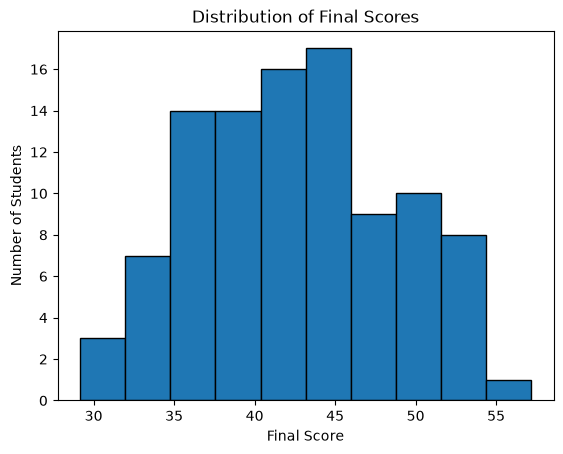

In [20]:


plt.hist(df_clean['final_score'], bins=10, edgecolor='black')

plt.title('Distribution of Final Scores')
plt.xlabel('Final Score')
plt.ylabel('Number of Students')

plt.show()

Observation: The histogram shows that most students' final scores are concentrated between approximately 35 and 45, with the highest frequency around 43–45. Only a few students have very low or very high scores. The distribution has one main peak and is slightly skewed to the right.

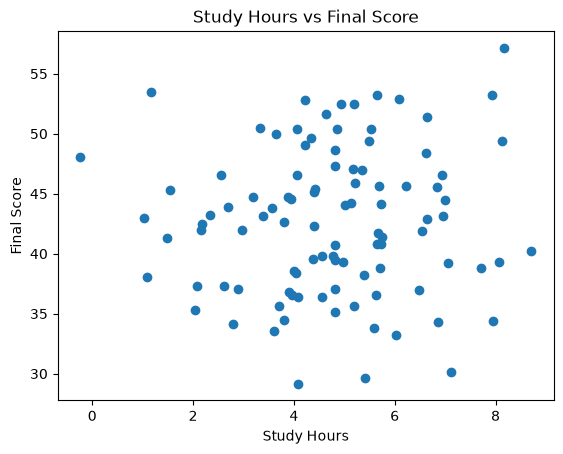

In [18]:
plt.scatter(df_clean['study_hours'], df_clean['final_score'])
plt.title('Study Hours vs Final Score')
plt.xlabel('Study Hours')
plt.ylabel('Final Score')
plt.show()


Observation: The scatter plot shows that students' final scores vary considerably even when they study similar hours. There is no clear linear trend, suggesting a weak relationship between study hours and final scores in the cleaned dataset.

In [19]:

correlation = df_clean['study_hours'].corr(df_clean['final_score'])
print(correlation)

0.04956992716567295


Critical Thinking: No, studying for 10 hours does not guarantee a specific score. Correlation does not provide an exact prediction or prove causation. A potential confounding variable is previous academic performance, because students with stronger prior knowledge may achieve higher scores regardless of how many hours they study.

In [15]:
x = df_clean[['study_hours', 'attendance', 'previous_mark']].iloc[0].to_numpy()

w = np.array([0.5, 0.2, 0.4])
b = 5

y = np.dot(w, x) + b

print("Student vector:", x)
print("Predicted score:", y)

Student vector: [ 4.8123416  70.84629258 75.36681041]
Predicted score: 51.72215347600458


Here I selected one student's feature values as a vector and calculated the predicted score using NumPy. Using the weight vector [0.5, 0.2, 0.4] and bias 5, the predicted score was 51.72.

Weights and Bias: The weights represent the contribution of each feature to the prediction. The bias is an additional value that shifts the predicted result.

In [16]:
#scaling 

df_clean['study_hours_scaled'] = (
    df_clean['study_hours'] - df_clean['study_hours'].mean()
) / df_clean['study_hours'].std()

df_clean['previous_mark_scaled'] = (
    df_clean['previous_mark'] - df_clean['previous_mark'].mean()
) / df_clean['previous_mark'].std()

print(df_clean[['study_hours_scaled', 'previous_mark_scaled']].head())


   study_hours_scaled  previous_mark_scaled
0            0.039465              0.274371
1            0.039465              0.460899
2            0.039465              0.940795
3            0.039465              0.913919
4            0.039465             -1.320291


K-Nearest Neighbors uses distances to find similar students. Without scaling, previous marks could have more influence because their values have a larger range than study hours. Standardization puts both features on a comparable scale so that one feature does not dominate the distance calculation simply because of its numerical range.